In [134]:
import sys, os
sys.path.append(os.path.abspath(".."))   # sys.path est la liste des dossiers dans lesquels Python va chercher les modules

import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import torchvision.transforms.functional as F
from PIL import Image
from utils import moving_average
from IPython.display import clear_output
import os

In [135]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [136]:
batch_size = 512
learning_rate = 3e-4
n_epochs = 10
n_classes = 5

In [137]:
class ImageDataset(Dataset):

    def __init__(self, split, transform=None):
        self.split = split
        self.transform = transform


    def __len__(self):
        files = [f for f in os.listdir(f"../data/dataset_crops_paires/{self.split}/sat/")]
        return len(files)
    

    def data_augm_pair(self, img1, img2):
        # flip horizontal
        if random.random() > 0.5:
            img1 = F.hflip(img1)
            img2 = F.hflip(img2)

        # flip vertical
        if random.random() > 0.5:
            img1 = F.vflip(img1)
            img2 = F.vflip(img2)

        # rotation
        angles = [0, 90, 180, 270]
        angle = random.choice(angles)
        img1 = F.rotate(img1, angle)
        img2 = F.rotate(img2, angle)

        return img1, img2


    def __getitem__(self, idx):
        crop = Image.open(f"../data/dataset_crops_paires/{self.split}/sat/crop_{idx}.png").convert("RGB")
        crop_burn = Image.open(f"../data/dataset_crops_paires/{self.split}/burn/crop_{idx}.png").convert("L")

        cropped_tensor = transforms.ToTensor()(crop)
        cropped_tensor_burn = transforms.ToTensor()(crop_burn)

        if self.transform:
            cropped_tensor = self.transform(cropped_tensor)
        
        cropped_tensor, cropped_tensor_burn = self.data_augm_pair(cropped_tensor, cropped_tensor_burn)

        cropped_segm = (cropped_tensor_burn * 255).to(torch.int64)

        return cropped_tensor, cropped_segm


transform = transforms.Compose([
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(split="train", transform=transform)
val_dataset = ImageDataset(split="val", transform=transform)


In [138]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=4, persistent_workers=True)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [139]:
print(len(train_dataset))
print(len(val_dataset))

111381
24386


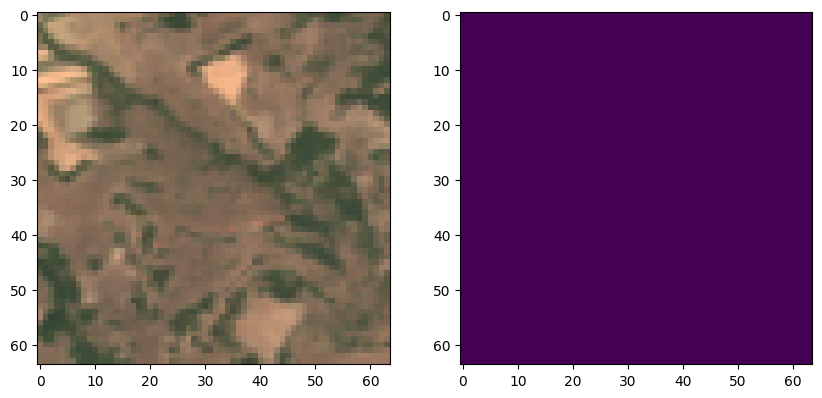

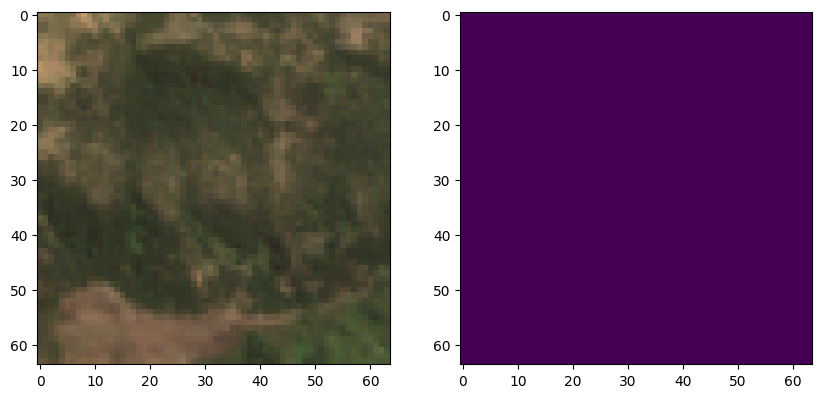

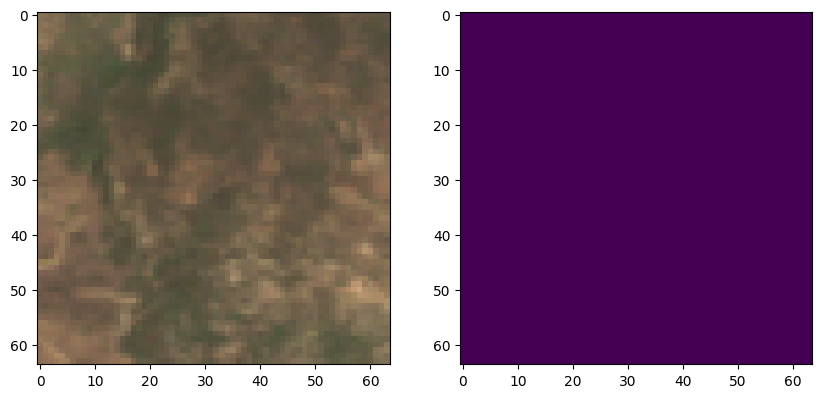

In [140]:
import matplotlib.pyplot as plt

for i in range(3):
    img1, img2 = next(iter(val_loader)) 

    # On prend le premier élément du batch
    img1 = img1[0].permute(1, 2, 0)
    img2 = img2[0][0]

    # Les images sont souvent normalisées, on remet dans [0,1]
    img1 = (img1 + 1) / 2

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img1)
    plt.subplot(1, 2, 2)
    plt.imshow(img2)
    plt.show()

In [141]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # Charger un modèle préentraîné

# checkpoint = torch.load("weights/resnet_sur_crops_sat_32x32_checkpoint10.pth")
# state_dict = checkpoint['model_state_dict']
# state_dict.pop('fc.weight')   # on ne charge pas les poids de la dernière couche car elle est différente
# state_dict.pop('fc.bias')
# resnet.load_state_dict(state_dict, strict=False)  # strict=False ignore les paramètres manquants

encoder = nn.Sequential(*list(resnet.children())[:-2])    # enlever les couches avgpool : AdaptiveAvgPool2d(output_size=(1, 1)) et fc : Linear(in_features=512, out_features=1000, bias=True)

decoder = nn.Sequential(
    nn.ConvTranspose2d(in_channels=512, out_channels=n_classes, kernel_size=8, stride=8)  # stride=8 pour remonter de H/8 -> H
)

model = nn.Sequential(
    encoder,
    decoder
)

model[0][6][0].conv1 = nn.Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), bias=False, dilation=2)
model[0][6][0].downsample[0] = nn.Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)

model[0][7][0].conv1 = nn.Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), bias=False, dilation=2)
model[0][7][0].downsample[0] = nn.Conv2d(256, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)

# print(model)

In [142]:
model = model.to(device)   # model.to(device) et pas model().to(device) car ici le model est déjà instancié
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, fused=True)   #, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=n_classes)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params/1e6:.6f} million")

train_loss_list, val_loss_list = [], []
train_iou_list, val_iou_list = [], []

Total parameters in the model: 11.340357 million


In [143]:
def get_IoUs(preds, targets):
    ious = []
    preds = preds.view(-1)
    targets = targets.view(-1)

    for cls in range(n_classes):
        pred_inds = (preds == cls)
        target_inds = (targets == cls)

        intersection = (pred_inds & target_inds).sum().item()
        union = (pred_inds | target_inds).sum().item()

        if union == 0:
            ious.append(float('nan'))  # classe absente, diviser par "nan" donne un "nan"
        else:
            ious.append(intersection / union)
    
    return ious

In [144]:
def ious_plots(train_ious_list, val_ious_list, w=3):

    # Transposer la liste pour avoir une liste par classe
    train_ious_per_class = list(zip(*train_ious_list))
    val_ious_per_class = list(zip(*val_ious_list))

    fig, axes = plt.subplots(2, 3, figsize=(20, 10))
    axes = axes.flatten()  # pour itérer facilement même si certaines cases restent vides


    for i in range(len(train_ious_per_class)):
        train_ious = train_ious_per_class[i]
        val_ious = val_ious_per_class[i]
        train_ious_smoothed = moving_average(train_ious, w=w)
        val_ious_smoothed = moving_average(val_ious, w=w)

        ax = axes[i]
        ax.plot(train_ious, alpha=0.2, color="blue")
        ax.plot(train_ious_smoothed, linestyle='--', color="blue")
        ax.plot(val_ious, alpha=0.2, color="red")
        ax.plot(val_ious_smoothed, linestyle='--', color="red")
        ax.set_title(f"Classe {i}")
        ax.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()


moyenne sur les 100 dernières valeurs:   train_loss: 0.20832540094852448   val_loss: 0.26894626021385193   train_iou_loss: 0.5692326426506042   val_iou_loss: 0.31834903359413147


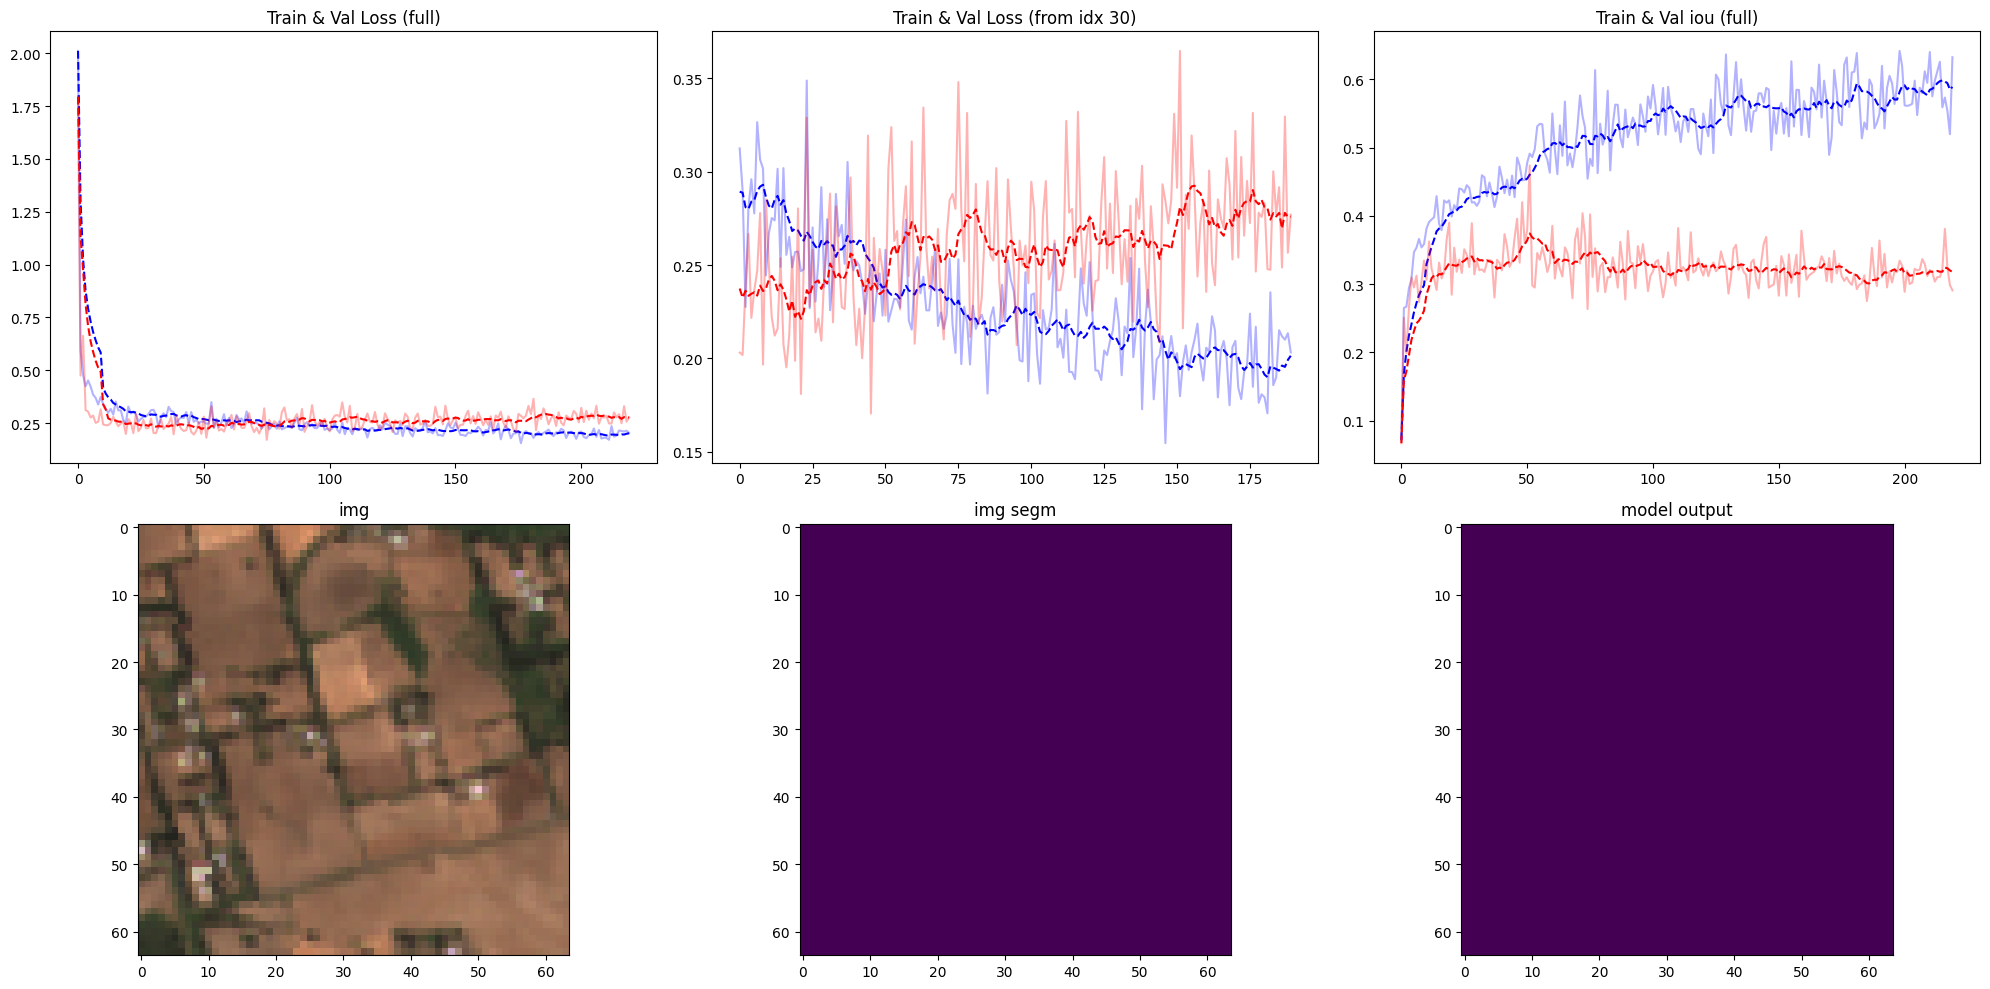

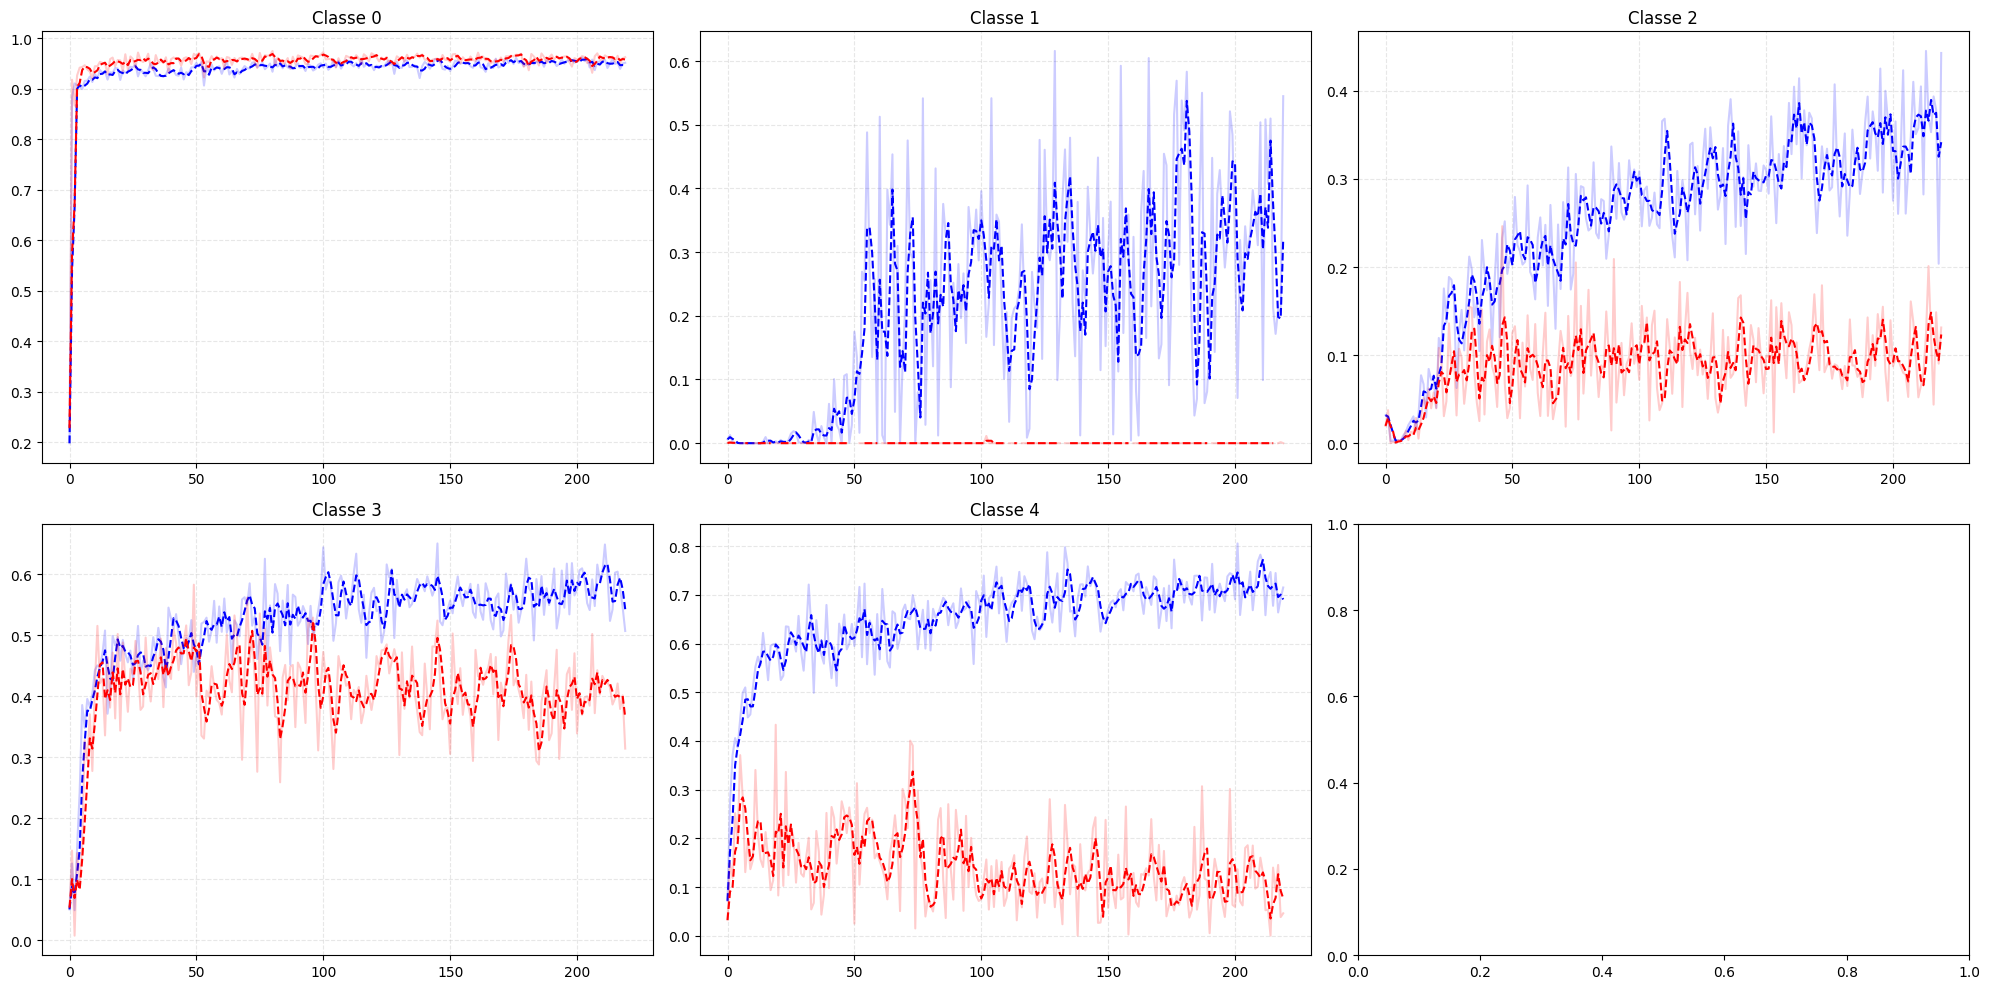

In [ ]:
for epoch in range(n_epochs):
    for i, (imgs, imgs_segm) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, imgs_segm = imgs.to(device), imgs_segm.to(device).squeeze(1)

        output = model(imgs)
        loss = criterion(output, imgs_segm)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()



        if i%10 == 0:

            train_loss_list.append(loss.item())

            # get train iou score
            with torch.no_grad():
                preds = output.argmax(dim=1)  # prendre la classe avec la probabilité la plus élevée
                ious = get_IoUs(preds, imgs_segm)
                train_iou_list.append(ious)

            # get val loss & val iou score
            model.eval()
            with torch.no_grad():
                try:
                    imgs, imgs_segm = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, imgs_segm = next(val_iterator)
                imgs, imgs_segm = imgs.to(device), imgs_segm.to(device).squeeze(1)
                output = model(imgs)
                val_loss = criterion(output, imgs_segm)
                val_loss_list.append(val_loss.item())

                preds = output.argmax(dim=1)  # prendre la classe avec la probabilité la plus élevée
                ious = get_IoUs(preds, imgs_segm)
                val_iou_list.append(ious)
            model.train()



    if epoch % 1 == 0:

        train_iou_list_mean = torch.tensor(train_iou_list).nanmean(dim=1).tolist()
        val_iou_list_mean = torch.tensor(val_iou_list).nanmean(dim=1).tolist()

        train_loss_list_smoothed = moving_average(train_loss_list)
        val_loss_list_smoothed = moving_average(val_loss_list)
        train_iou_list_mean_smoothed = moving_average(train_iou_list_mean)
        val_iou_list_mean_smoothed = moving_average(val_iou_list_mean)

        clear_output(wait=True)  # efface l'ancien plot

        print(f"moyenne sur les 100 dernières valeurs:   train_loss: {torch.tensor([train_loss_list[-100:]]).mean()}   val_loss: {torch.tensor([val_loss_list[-100:]]).mean()}   train_iou_loss: {torch.tensor([train_iou_list[-100:]]).nanmean()}   val_iou_loss: {torch.tensor([val_iou_list[-100:]]).nanmean()}")

        imgs, imgs_segm = next(iter(train_loader))
        imgs_segm = imgs_segm.squeeze(1)
        output = model(imgs.to(device))
        output = output.argmax(dim=1).cpu()  # prendre la classe avec la probabilité la plus élevée

        plt.figure(figsize=(20, 10))

        plt.subplot(2, 3, 1)
        plt.plot(train_loss_list, c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
        plt.plot(val_loss_list, c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
        plt.title("Train & Val Loss (full)")

        plt.subplot(2, 3, 2)
        plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
        plt.plot(val_loss_list[30:], c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
        plt.title("Train & Val Loss (from idx 30)")

        plt.subplot(2, 3, 3)
        plt.plot(train_iou_list_mean, c="blue", alpha=0.3)
        plt.plot(train_iou_list_mean_smoothed, c="blue", linestyle='--')
        plt.plot(val_iou_list_mean, c="red", alpha=0.3)
        plt.plot(val_iou_list_mean_smoothed, c="red", linestyle='--')
        plt.title("Train & Val iou (full)")

        plt.subplot(2, 3, 4)
        plt.imshow((imgs[0].permute(1, 2, 0)+1)/2)
        plt.title("img")

        plt.subplot(2, 3, 5)
        plt.imshow(imgs_segm[0])
        plt.title("img segm")

        plt.subplot(2, 3, 6)
        plt.imshow(output[0])
        plt.title("model output")

        plt.tight_layout()  # ajuste l'espacement
        plt.show()

        ious_plots(train_iou_list, val_iou_list)


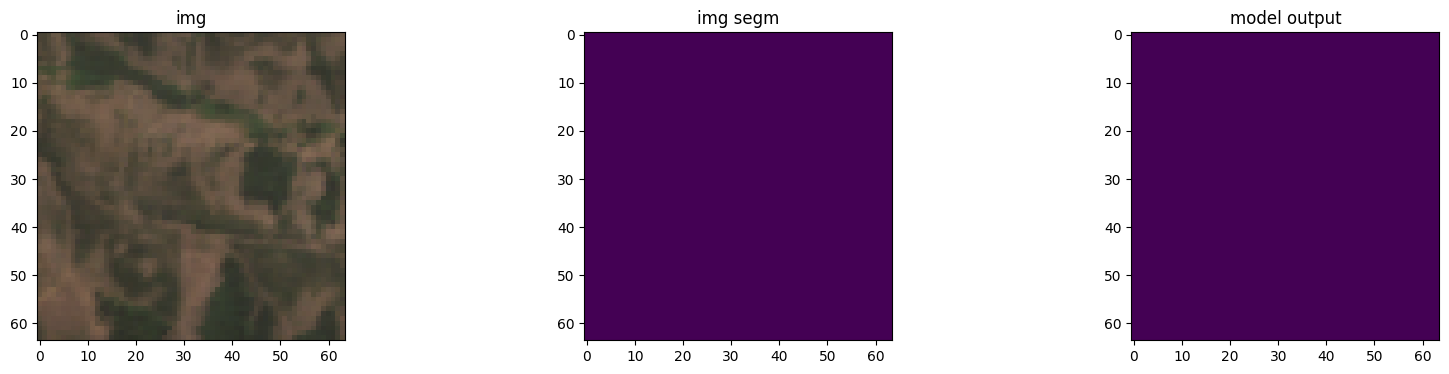

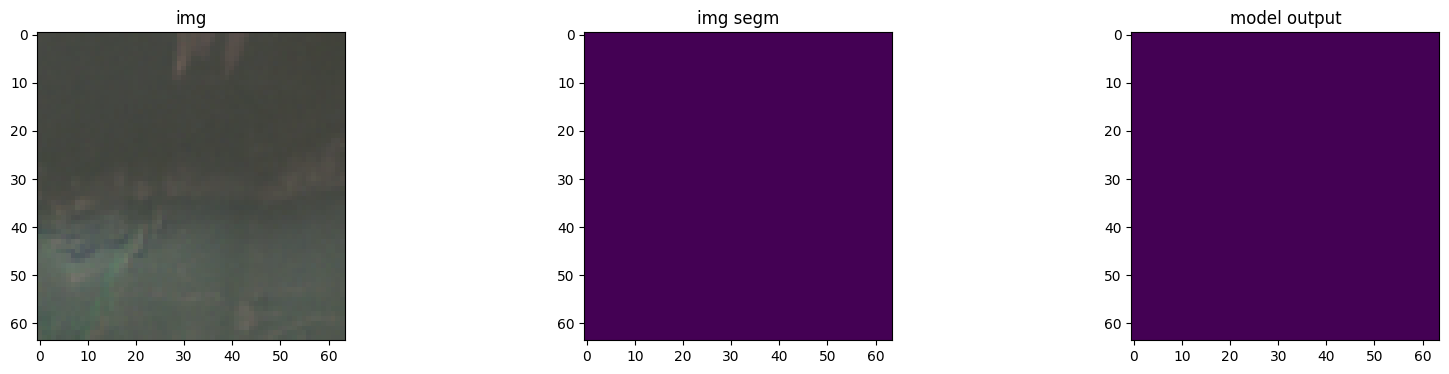

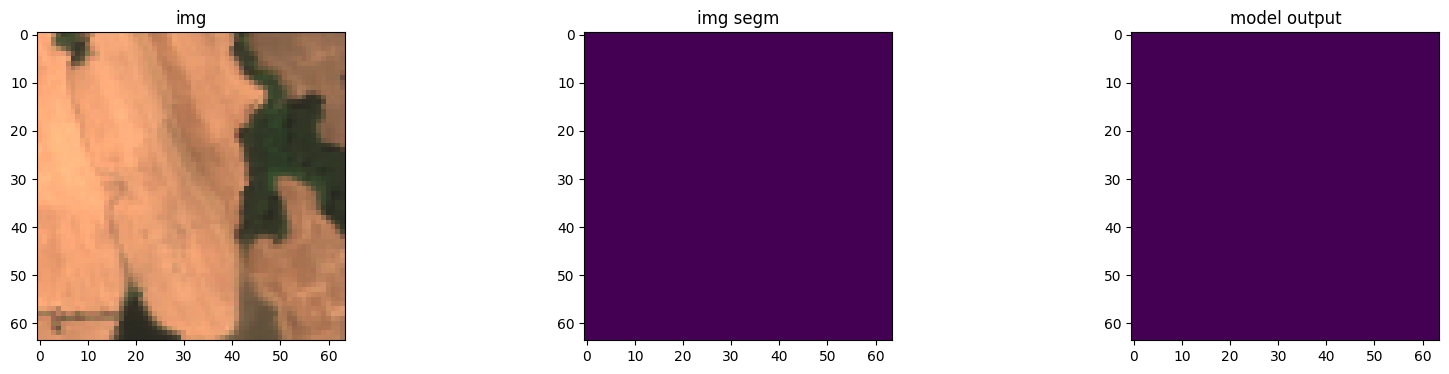

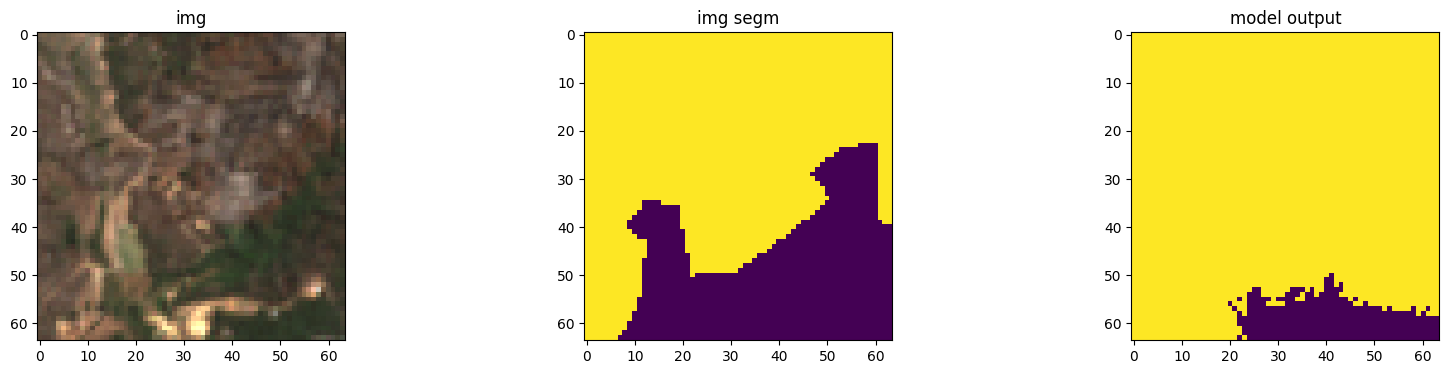

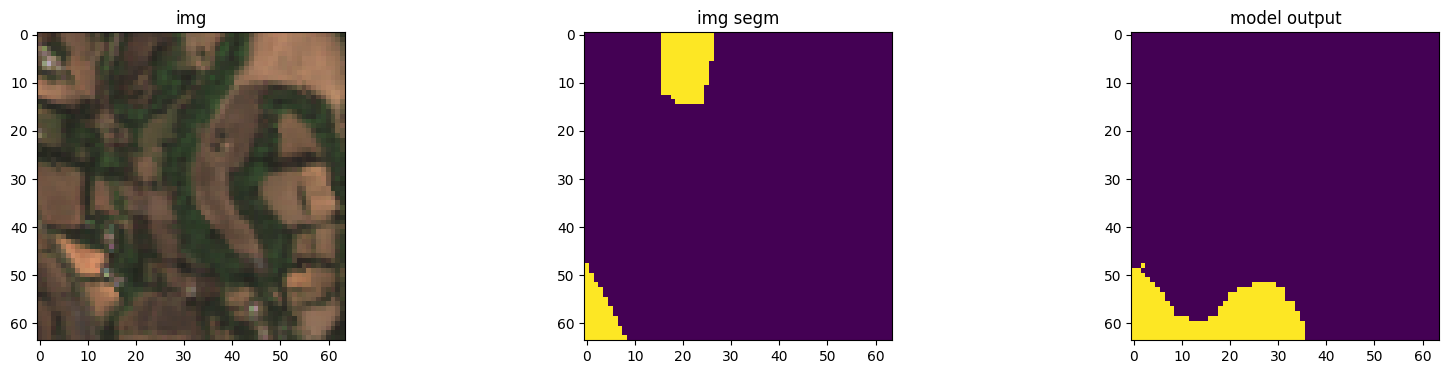

In [149]:
imgs, imgs_segm = next(iter(train_loader))
imgs_segm = imgs_segm.squeeze(1)
output = model(imgs.to(device))
output = output.argmax(dim=1).cpu()  # prendre la classe avec la probabilité la plus élevée

for i in range(5):
    plt.figure(figsize=(20, 4))
    plt.subplot(1, 3, 1)
    plt.imshow((imgs[i].permute(1, 2, 0)+1)/2)
    plt.title("img")
    plt.subplot(1, 3, 2)
    plt.imshow(imgs_segm[i])
    plt.title("img segm")
    plt.subplot(1, 3, 3)
    plt.imshow(output[i])
    plt.title("model output")
    plt.show()